# 01 · Data Profiling & Quality Audit

**Objective:** understand every table before changing anything, and record each data-quality problem in an issue log. That log drives the cleaning step (`preprocessing.ipynb`).

**Approach**
1. Raw files in `wellbeingdata/` are read-only. All cleaning happens in the preprocessing step.
2. Every table is loaded as strings (`dtype=str`), so pandas can't silently convert, round or fill values and hide problems.
3. Every finding is recorded with `log_issue(...)` and exported to `reports/data_quality_log.csv`. Each entry has its evidence, a severity, and a proposed fix.

Each section opens with the questions it answers (❓). Findings are written up beneath the outputs.

In [1]:
import json, re
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

RAW = Path("wellbeingdata")
REPORTS = Path("reports"); REPORTS.mkdir(exist_ok=True)

users   = pd.read_csv(RAW / "users.csv", dtype=str)
events  = pd.read_csv(RAW / "events.csv", dtype=str)
assess  = pd.read_csv(RAW / "assessments.csv", dtype=str)
assign  = pd.read_csv(RAW / "experiment_assignments.csv", dtype=str)
content = pd.read_csv(RAW / "content.csv", dtype=str)
mkt     = pd.read_csv(RAW / "marketing_spend.csv", dtype=str)

for name, df in [("users", users), ("events", events), ("assessments", assess),
                 ("assignments", assign), ("content", content), ("marketing", mkt)]:
    print(f"{name:12s} {df.shape}")

users        (15146, 12)
events       (603906, 9)
assessments  (15574, 26)
assignments  (4306, 5)
content      (120, 5)
marketing    (306, 6)


## Helpers: column profiler and issue log

In [2]:
def profile(df, max_examples=5):
    """One row per column: nulls, cardinality, and example values."""
    rows = []
    for c in df.columns:
        s = df[c]
        rows.append({
            "column": c,
            "n_null": s.isna().sum(),
            "pct_null": round(100 * s.isna().mean(), 2),
            "n_unique": s.nunique(dropna=True),
            "examples": list(s.dropna().unique()[:max_examples]),
        })
    return pd.DataFrame(rows)

def shape_pattern(s):
    """Replace digits with 'd' and letters with 'a' to reveal format families in a string column."""
    return s.fillna("<NULL>").str.replace(r"[A-Za-z]", "a", regex=True).str.replace(r"\d", "d", regex=True)

ISSUES = []
def log_issue(table, column, issue, evidence, severity, proposed_fix):
    """severity: high (changes conclusions) / medium / low"""
    ISSUES.append(dict(table=table, column=column, issue=issue, evidence=evidence,
                       severity=severity, proposed_fix=proposed_fix))

# Usage:
# log_issue("users", "user_id", "<what is wrong>", "<evidence: counts / %>", "high|medium|low", "<proposed fix>")

---
## 1. `users`
❓ Is `user_id` really unique? If it isn't, how do the duplicates differ from the originals?
❓ Do categorical columns use one consistent set of labels?
❓ Which columns are missing data, and is that missingness random or structural (missing for a reason)?

In [3]:
profile(users)

,column,n_null,pct_null,n_unique,examples
0,user_id,0,0.00,15006,"[L101349, u_ae1e9413b8, u_63976134b9, u_ff2df6..."
1,signup_ts,0,0.00,15132,"[2026-06-14T10:49:57Z, 2026-10-19T15:19:04Z, 2..."
2,platform,0,0.00,6,"[Web, ios, android, web, Android]"
3,signup_app_version,0,0.00,6,"[4.9.0, 5.2.0, 5.1.0, 5.0.0, 5.1.1]"
4,country,0,0.00,11,"[BR, US, AU, ZA, GB]"
5,timezone,0,0.00,15,"[America/Sao_Paulo, America/Chicago, Australia..."
6,age_band,1052,6.95,6,"[55-64, 45-54, 35-44, 65+, 25-34]"
7,gender,6,0.04,4,"[male, female, nonbinary, prefer_not_to_say]"
8,acquisition_channel,0,0.00,6,"[paid_social, app_store_search, partner_org, o..."
9,meditation_experience,2119,13.99,3,"[none, regular, some]"


In [4]:
print("rows:", len(users), "| unique user_id:", users.user_id.nunique())
dup_ids = users.loc[users.user_id.duplicated(keep=False)].sort_values("user_id")
dup_ids.head(10)

rows: 15146 | unique user_id: 15006


,user_id,signup_ts,platform,signup_app_version,country,timezone,age_band,gender,acquisition_channel,meditation_experience,primary_goal,source_system
10330,L100033,2026-06-26T15:17:51Z,Web,4.9.0,US,America/Chicago,18-24,male,app_store_search,none,general_wellbeing,legacy
1103,L100033,2026-06-26T15:18:32Z,web,4.9.0,US,America/Chicago,18-24,male,app_store_search,none,general_wellbeing,core
14905,L100265,2026-06-19T22:28:17Z,iPhone,4.8.0,US,America/Chicago,18-24,prefer_not_to_say,organic,regular,stress,legacy
1603,L100265,2026-06-19T22:29:14Z,ios,4.8.0,US,America/Chicago,18-24,prefer_not_to_say,organic,regular,stress,core
6995,L100284,2026-06-05T15:04:46Z,iPhone,4.8.0,US,America/New_York,65+,female,referral,some,stress,legacy
348,L100284,2026-06-05T15:05:08Z,ios,4.8.0,US,America/New_York,65+,female,referral,some,stress,core
8685,L100504,2026-06-08T15:02:12Z,Android,4.8.0,BR,America/Sao_Paulo,25-34,male,partner_org,none,focus,legacy
14697,L100504,2026-06-08T15:03:18Z,android,4.8.0,BR,America/Sao_Paulo,25-34,male,partner_org,none,focus,core
2307,L100526,2026-06-12T18:28:08Z,web,4.9.0,US,America/New_York,55-64,male,referral,regular,focus,core
11927,L100526,2026-06-12T18:26:40Z,Web,4.9.0,US,America/New_York,55-64,male,referral,regular,focus,legacy


In [ ]:
log_issue("users", "user_id",
          "Duplication due to source system, repeats for core and legacy entries",
          "",
          "high",
          "fix duplicates by removing legacy entries")

In [11]:
for c in ["platform", "signup_app_version", "country", "age_band", "gender",
          "acquisition_channel", "meditation_experience", "primary_goal", "source_system"]:
    print(f"\n--- {c}"); print(users[c].value_counts(dropna=False).to_string())


--- platform
platform
ios        6560
android    5065
web        1592
iPhone      948
Android     752
Web         229

--- signup_app_version
signup_app_version
5.0.0    3270
4.9.0    3151
5.1.0    2774
4.8.0    2736
5.2.0    2395
5.1.1     820

--- country
country
US    7987
IN    1219
GB    1208
CA     892
BR     675
MX     618
AU     602
DE     575
SG     491
ZA     459
FR     420

--- age_band
age_band
25-34    3822
35-44    3227
45-54    2381
18-24    2026
55-64    1695
NaN      1052
65+       943

--- gender
gender
female               9133
male                 4943
prefer_not_to_say     593
nonbinary             471
NaN                     6

--- acquisition_channel
acquisition_channel
organic             4824
paid_social         3683
app_store_search    2689
partner_org         2201
referral            1743
unknown                6

--- meditation_experience
meditation_experience
none       6140
some       4970
NaN        2119
regular    1917

--- primary_goal
primary_goal
str

In [12]:
log_issue("users", "platform",
          "Inconsistent platform labels (iPhone/ios, Android/android, Web/web)",
          "948 'iPhone', 752 'Android', 229 'Web' alongside lowercase labels",
          "medium",
          "Map all labels to lowercase ios/android/web")

In [13]:
# ID formats and timestamp formats
print(shape_pattern(users.user_id).value_counts().head(), "\n")
print(shape_pattern(users.signup_ts).value_counts().head())

user_id
adddddd         2069
a_dddddddddd     108
a_dddddadddd      93
a_dddadddddd      86
a_addddddddd      79
Name: count, dtype: int64 

signup_ts
dddd-dd-ddadd:dd:dda    15146
Name: count, dtype: int64


In [15]:
#users with null counts
users.isnull().sum()

user_id                     0
signup_ts                   0
platform                    0
signup_app_version          0
country                     0
timezone                    0
age_band                 1052
gender                      6
acquisition_channel         0
meditation_experience    2119
primary_goal             2119
source_system               0
dtype: int64

In [19]:
log_issue("users", "age_band, medidation_exp, primary_goal",
          "Null values present in critical columns",
          "age_band: 1052 nulls, meditation_experience: 2119 nulls, primary_goal: 2119 nulls",
          "medium",
          "Investigate and fill or remove null values as appropriate")

In [18]:
#print rows where age_band is null
users[users["meditation_experience"].isnull()]

,user_id,signup_ts,platform,signup_app_version,country,timezone,age_band,gender,acquisition_channel,meditation_experience,primary_goal,source_system
2,u_63976134b9,2026-09-21T07:11:26Z,ios,5.1.0,AU,Australia/Sydney,35-44,female,app_store_search,NaN,NaN,core
4,u_f48876226a,2026-09-20T16:26:54Z,android,5.0.0,BR,America/Sao_Paulo,NaN,male,paid_social,NaN,NaN,core
7,u_5754d78b00,2026-09-28T09:43:16Z,android,5.1.1,AU,Australia/Sydney,NaN,female,paid_social,NaN,NaN,core
15,u_108056e63d,2026-09-25T09:27:16Z,android,5.1.1,SG,Asia/Singapore,25-34,male,app_store_search,NaN,NaN,core
21,u_0768b8acec,2026-10-26T18:02:13Z,android,5.2.0,ZA,Africa/Johannesburg,25-34,female,app_store_search,NaN,NaN,core
...,...,...,...,...,...,...,...,...,...,...,...,...
15119,u_4850b6d045,2026-08-23T16:22:44Z,ios,5.0.0,GB,Europe/London,25-34,female,partner_org,NaN,NaN,core
15122,u_6e50f36c74,2026-07-22T12:36:17Z,android,4.9.0,US,America/New_York,25-34,female,paid_social,NaN,NaN,core
15127,u_725b089209,2026-08-06T16:19:49Z,android,4.9.0,GB,Europe/London,45-54,female,paid_social,NaN,NaN,core
15137,u_3a194293d1,2026-08-02T13:17:43Z,ios,4.9.0,GB,Europe/London,35-44,male,paid_social,NaN,NaN,core


In [14]:
# Is missingness related to anything else? Example: onboarding answers vs source system / platform
users.assign(exp_missing=users.meditation_experience.isna()) \
     .groupby(["source_system", "platform"]).exp_missing.mean().round(3).unstack()

platform,Android,Web,android,iPhone,ios,web
source_system,,,,,,
core,NaN,NaN,0.162,NaN,0.138,0.112
legacy,0.128,0.1,NaN,0.099,NaN,NaN


In [21]:
ISSUES=[]
log_issue("users", "user_id",
          "Legacy users duplicated by migration: copies labeled source_system='core'",
          "15,146 rows vs 15,006 unique ids; 140 dupes, all L-prefixed ids signed up before 2026-07-01; "
          "copy has lowercase platform and signup_ts +1-90s",
          "high",
          "Keep the legacy row, drop the 'core' copy")

log_issue("users", "meditation_experience, primary_goal",
          "Structurally missing: onboarding answers only exist if onboarding was completed",
          "2,119 nulls in both columns, same users; matches users without an onboarding_complete event",
          "medium",
          "Fill with 'not_answered' and add completed_onboarding flag; do not impute")

log_issue("users", "age_band",
          "Optional self-reported field, ~7% missing",
          "1,052 nulls",
          "low",
          "Use 'unknown' category; do not impute")

In [22]:
#print different values of acquisition_channel
print(users['acquisition_channel'].value_counts())

acquisition_channel
organic             4824
paid_social         3683
app_store_search    2689
partner_org         2201
referral            1743
unknown                6
Name: count, dtype: int64


In [23]:
#print users with unknown acquisition_channel
print(users[users['acquisition_channel'] == 'unknown'])

            user_id             signup_ts platform signup_app_version country         timezone age_band gender acquisition_channel meditation_experience primary_goal source_system
638    u_d5f87a34f6  2026-09-07T00:00:00Z  android              5.0.0      US  America/Chicago      NaN    NaN             unknown                   NaN          NaN          core
5833   u_40fdb77c55  2026-09-10T00:00:00Z      ios              5.0.0      US  America/Chicago      NaN    NaN             unknown                   NaN          NaN          core
7315   u_e066ce6bd5  2026-09-06T00:00:00Z      ios              5.0.0      US  America/Chicago      NaN    NaN             unknown                   NaN          NaN          core
7632   u_2a030ebeda  2026-09-01T00:00:00Z  android              5.0.0      US  America/Chicago      NaN    NaN             unknown                   NaN          NaN          core
10810  u_86e30ec33d  2026-09-03T00:00:00Z      ios              5.0.0      US  America/Chicago      

In [24]:
log_issue("users/events", "user_id",
          "6 internal/test accounts mixed with real users",
          "acquisition_channel='unknown'; no app_install/onboarding events; no profile; "
          "80-300 practice_complete/day with ~5s durations",
          "high",
          "Exclude these user_ids from all tables; keep an is_internal flag for traceability")

---
## 2. `events`
❓ How many timestamp *formats* are there? Which rows have each one?
❓ Do the event names match the README's tracking plan? Which names don't, and when do they show up?
❓ Do the `properties` keys stay the same within an event type?
❓ Are there duplicates? Check both exact copies and near-copies a second or two apart.
❓ Are there users whose activity is humanly impossible?
❓ Are there dates or volumes that look wrong when you plot them over time?

In [25]:
profile(events)

,column,n_null,pct_null,n_unique,examples
0,event_id,0,0.00,603906,"[7aa23492064a9e2a, cd3dc8b6cffb41e4, 68a9e49bb..."
1,user_id,664,0.11,15006,"[L106033, L105316, L107222, L110089, L114096]"
2,event_name,0,0.00,14,"[app_install, app_open, onboarding_start, onbo..."
3,event_ts,0,0.00,601696,"[2026-06-01 08:38:00, 2026-06-01 08:38:03, 202..."
4,session_id,15701,2.60,164270,"[L106033-s1, L105316-s1, L107222-s1, L110089-s..."
5,platform,0,0.00,6,"[iPhone, Web, Android, android, ios]"
6,app_version,0,0.00,6,"[4.8.0, 4.9.0, 5.0.0, 5.1.0, 5.1.1]"
7,schema_version,0,0.00,2,"[1, 2]"
8,properties,0,0.00,23200,"[{}, {""flow"": ""standard""}, {""experience"": ""som..."


In [34]:
events

,event_id,user_id,event_name,event_ts,session_id,platform,app_version,schema_version,properties,ts_pattern
0,7aa23492064a9e2a,L106033,app_install,2026-06-01 08:38:00,L106033-s1,iPhone,4.8.0,1,{},dddd-dd-dd dd:dd:dd
1,cd3dc8b6cffb41e4,L106033,app_open,2026-06-01 08:38:03,L106033-s1,iPhone,4.8.0,1,{},dddd-dd-dd dd:dd:dd
2,68a9e49bbc88c020,L106033,onboarding_start,2026-06-01 08:38:09,L106033-s1,iPhone,4.8.0,1,"{""flow"": ""standard""}",dddd-dd-dd dd:dd:dd
3,7ed21b04c0dcde1c,L105316,app_install,2026-05-31 23:40:58,L105316-s1,iPhone,4.8.0,1,{},dddd-dd-dd dd:dd:dd
4,38de3f7d221a2910,L105316,app_open,2026-05-31 23:41:01,L105316-s1,iPhone,4.8.0,1,{},dddd-dd-dd dd:dd:dd
...,...,...,...,...,...,...,...,...,...,...
603901,286db2b82a7eafc6,u_8d069375f5,app_open,2026-11-15T23:56:40.868Z,u_8d069375f5-s86,android,5.2.0,2,{},dddd-dd-ddadd:dd:dd.ddda
603902,17e0e22bfe073a1c,u_3a53d43724,practice_start,2026-11-15T23:56:51.733Z,u_3a53d43724-s63,android,5.2.0,2,"{""contentId"": ""c_033""}",dddd-dd-ddadd:dd:dd.ddda
603903,71e9131c89ee8b1e,u_8d069375f5,practice_start,2026-11-15T23:57:03.868Z,u_8d069375f5-s86,android,5.2.0,2,"{""contentId"": ""c_083""}",dddd-dd-ddadd:dd:dd.ddda
603904,252d82f1a34849f0,u_84b8d6cbc7,practice_complete,2026-11-15T23:58:19.303Z,u_84b8d6cbc7-s38,ios,5.2.0,2,"{""contentId"": ""c_037"", ""durationMs"": 891000}",dddd-dd-ddadd:dd:dd.ddda


In [27]:
print(events.event_name.value_counts().to_string(), "\n")
print(events.platform.value_counts().to_string())

event_name
app_open                167203
practice_start          147808
practice_complete       123411
meditation_started       42650
meditation_completed     36098
notification_open        18855
assessment_complete      15482
app_install              15266
onboarding_start         15253
onboarding_complete      13119
reminder_set              4501
goal_selected             2023
plan_created              2018
notification_opt_out       219 

platform
ios        285332
android    234090
web         52593
iPhone      16080
Android     12344
Web          3467


In [28]:
# Timestamp format families
events["ts_pattern"] = shape_pattern(events.event_ts)
events.ts_pattern.value_counts()

ts_pattern
dddd-dd-ddadd:dd:dd.ddda    572015
dddd-dd-dd dd:dd:dd          31891
Name: count, dtype: int64

In [46]:
# print rows with dddd-dd-dd dd:dd:dd ts_pattern format, and value count app_version, plstform on the filtered rows
print(events[events['ts_pattern'].str.len() == 19][['app_version', 'platform']].value_counts())

app_version  platform
4.8.0        iPhone      16080
             Android     12344
4.9.0        Web          3467
Name: count, dtype: int64


In [47]:
# print rows with dddd-dd-ddadd:dd:dd.ddda ts_pattern format, and value count app_version on the filtered rows, without regex
print(events[events['ts_pattern'].str.len() == 24][['app_version', 'platform']].value_counts())

app_version  platform
5.2.0        ios         99687
5.1.0        ios         84260
5.2.0        android     71341
5.0.0        ios         47472
5.1.1        android     44067
4.9.0        ios         41503
5.1.0        android     38180
5.0.0        web         37204
4.9.0        android     33810
5.0.0        android     33559
4.9.0        web         15389
4.8.0        android     13133
             ios         12410
Name: count, dtype: int64


In [48]:
log_issue("events", "event_ts",
          "2 types of timestamps",
          "from ts_pattern with length 19 and 24",
          "medium",
          "Older versions 4.8 and 4.9 have timestamps with length 19 while all versions had timestamps with length 24")

In [49]:
#also check the dddd-dd-ddadd:dd:dd.ddda ts_pattern with source_system from users table
print(events[events['ts_pattern'].str.len() == 24].merge(users[['user_id', 'source_system']], on='user_id')[['app_version', 'platform', 'source_system']].value_counts())

app_version  platform  source_system
5.2.0        ios       core             94469
5.1.0        ios       core             80242
5.2.0        android   core             66575
5.0.0        ios       core             43058
5.1.1        android   core             41557
5.1.0        android   core             36155
5.0.0        web       core             35200
4.9.0        ios       core             32263
5.0.0        android   core             29994
4.9.0        android   core             26340
             web       core             12359
             ios       legacy           10122
             android   legacy            8022
4.8.0        android   core              7532
             ios       core              7378
             android   legacy            5979
5.2.0        ios       legacy            5642
4.8.0        ios       legacy            5507
5.2.0        android   legacy            5068
5.0.0        ios       legacy            4818
5.1.0        ios       legacy            43

In [50]:
#also check the dddd-dd-dd dd:dd:dd ts_pattern with source_system from users table
print(events[events['ts_pattern'].str.len() == 19].merge(users[['user_id', 'source_system']], on='user_id')[['app_version', 'platform', 'source_system']].value_counts())

app_version  platform  source_system
4.8.0        iPhone    legacy           16080
             Android   legacy           12344
4.9.0        Web       legacy            3467
4.8.0        iPhone    core              1225
             Android   core               874
4.9.0        Web       core               256
Name: count, dtype: int64


In [51]:
# Which users / platforms produce each timestamp format?
pd.crosstab(events.ts_pattern, events.platform)

platform,Android,Web,android,iPhone,ios,web
ts_pattern,,,,,,
dddd-dd-dd dd:dd:dd,12344,3467,0,16080,0,0
dddd-dd-ddadd:dd:dd.ddda,0,0,234090,0,285332,52593


In [52]:
# Parse timestamps (format="mixed" for now; you decide the correct handling in Step 2)
events["ts_parsed"] = pd.to_datetime(events.event_ts, format="mixed", utc=True, errors="coerce")
print("unparseable:", events.ts_parsed.isna().sum())
print("min:", events.ts_parsed.min(), "| max:", events.ts_parsed.max())
events.ts_parsed.dt.year.value_counts().sort_index()

unparseable: 0
min: 2001-06-03 12:39:32+00:00 | max: 2027-11-15 19:51:30.212000+00:00


ts_parsed
2001       938
2026    602028
2027       940
Name: count, dtype: int64

In [53]:
# Event names x schema version x app version
pd.crosstab([events.event_name], [events.schema_version])

schema_version,1,2
event_name,,
app_install,5900,9366
app_open,41290,125913
assessment_complete,5330,10152
goal_selected,59,1964
meditation_completed,36098,0
meditation_started,42650,0
notification_open,4039,14816
notification_opt_out,67,152
onboarding_complete,5107,8012


In [56]:
#value and counts of meditation_started and meditation_completed
print(events[events['event_name'] == 'meditation_started'].value_counts())
print(events[events['event_name'] == 'meditation_completed'].value_counts())

event_id          user_id       event_name          event_ts                  session_id       platform  app_version  schema_version  properties               ts_pattern                ts_parsed                       
00019c00a4961d32  u_a4a186c4de  meditation_started  2026-07-26T04:56:13.307Z  u_a4a186c4de-s6  ios       4.9.0        1               {"content_id": "c_069"}  dddd-dd-ddadd:dd:dd.ddda  2026-07-26 04:56:13.307000+00:00    1
00024fe7e222eb6a  u_5ad42cba6b  meditation_started  2027-07-30T11:54:54.481Z  u_5ad42cba6b-s3  ios       4.9.0        1               {"content_id": "c_060"}  dddd-dd-ddadd:dd:dd.ddda  2027-07-30 11:54:54.481000+00:00    1
0002cb723a01db5a  L107784       meditation_started  2026-06-28 18:52:59       L107784-s19      iPhone    4.8.0        1               {"content_id": "c_023"}  dddd-dd-dd dd:dd:dd       2026-06-28 18:52:59+00:00           1
00079d17b6e6a754  L103907       meditation_started  2026-07-07T12:32:06.826Z  L103907-s8       ios       4.8.0   

In [80]:
log_issue("events", "event_name",
          "Field values doesn't match the one in readme",
          "meditation_started and meditation_completed are missing in readme",
          "medium",
          "They only show up when schema_version is 1, and practice_start and practice_complete catch them now.")

In [62]:
#print unique value of event properties
print(events['properties'].unique())
events['properties'].value_counts()

['{}' '{"flow": "standard"}' '{"experience": "some", "goal": "sleep"}' ...
 '{"contentId": "c_073", "durationMs": 1218000}'
 '{"contentId": "c_094", "durationMs": 1184000}'
 '{"contentId": "c_035", "durationMs": 1851000}']


properties
{}                                               201543
{"flow": "standard"}                              13036
{"wave": "baseline"}                              11263
{"wave": "week4"}                                  2816
{"experience": "none", "goal": "stress"}           2313
                                                  ...  
{"contentId": "c_096", "durationMs": 1666000}         1
{"content_id": "c_083", "duration_sec": 842}          1
{"contentId": "c_025", "durationMs": 1147000}         1
{"contentId": "c_022", "durationMs": 1208000}         1
{"contentId": "c_035", "durationMs": 1851000}         1
Name: count, Length: 23200, dtype: int64

In [63]:
# count properties having durationMs as the key
events['properties'].apply(lambda x: 'durationMs' in x).sum()

np.int64(123411)

In [57]:
# Property keys per event type & schema version
events["prop_keys"] = events.properties.map(lambda p: ",".join(sorted(json.loads(p).keys())) if isinstance(p, str) else "<NULL>")
events.groupby(["event_name", "schema_version"]).prop_keys.value_counts().to_frame("n")

n
event_name           schema_version prop_keys                      
app_install          1                                         5900
                     2                                         9366
app_open             1                                        41290
                     2                                       125913
assessment_complete  1              wave                       5330
                     2              wave                      10152
goal_selected        1              goal                         59
                     2              goal                       1964
meditation_completed 1              content_id,duration_sec   36098
meditation_started   1              content_id                42650
notification_open    1                                         4039
                     2                                        14816
notification_opt_out 1                                           67
                     2                                          152
onboarding_complete  1              experience,goal            5107
                     2              experience,goal            8012
onboarding_start     1              flow                       5872
                     2              flow                       9381
plan_created         1              plan_length_days             59
                     2              plan_length_days           1959
practice_complete    2              contentId,durationMs     123411
practice_start       2              contentId                147808
reminder_set         1              reminder_time              1665
                     2              reminder_time              2836

In [82]:
log_issue("events", "event_name",
          "Yes, the `properties` keys stay the same within an event type",
          "","","")

In [83]:
# Duration values: units sanity check (look at the magnitudes)
def get_duration(p):
    d = json.loads(p)
    return d.get("duration_sec", d.get("durationMs"))
comp = events[events.event_name.isin(["practice_complete", "meditation_completed"])].copy()
comp["duration_raw"] = comp.properties.map(get_duration).astype(float)
comp.groupby("schema_version").duration_raw.describe()

,count,mean,std,min,25%,50%,75%,max
schema_version,,,,,,,,
1,36098.0,690.085683,412.479248,5.0,301.0,602.0,920.0,1889.0
2,123411.0,582912.495645,449845.579498,5000.0,276000.0,556000.0,893000.0,1889000.0


In [84]:
log_issue("events", "event_name",
          "Time in sec in version 1, while duration in ms in version 2",
          "Mean values",
          "High",
          "Convert ms to sec in newer version")

In [85]:
# Exact duplicates (ignoring event_id)
key_cols = ["user_id", "event_name", "event_ts", "session_id", "properties"]
print("exact dupes:", events.duplicated(subset=key_cols).sum())

# Near-duplicates: same user/event/session/properties within 3 seconds
e = events.dropna(subset=["ts_parsed"]).sort_values(["user_id", "event_name", "session_id", "properties", "ts_parsed"])
gap = e.groupby(["user_id", "event_name", "session_id", "properties"]).ts_parsed.diff().dt.total_seconds()
near = e[gap.between(0, 3)]
print("near-dupes (<=3s):", len(near))
near.platform.value_counts()

exact dupes: 163
near-dupes (<=3s): 10691


platform
android    7624
ios        2147
web         387
Android     384
iPhone      116
Web          33
Name: count, dtype: int64

In [86]:
log_issue("events", '["user_id", "event_name", "event_ts", "session_id", "properties"]',
          "There are 163 exact dupes while 10691 near dupes",
          "Count on groups except event_id, but what can be the reason for near duplicates?",
          "High",
          "Remove exact and near duplicates from the dataset")

In [87]:
# Null user_id events
print(events.user_id.isna().sum())
events[events.user_id.isna()].event_name.value_counts()

664


event_name
app_open    664
Name: count, dtype: int64

In [94]:
events

,event_id,user_id,event_name,event_ts,session_id,platform,app_version,schema_version,properties,ts_pattern,ts_parsed,prop_keys
0,7aa23492064a9e2a,L106033,app_install,2026-06-01 08:38:00,L106033-s1,iPhone,4.8.0,1,{},dddd-dd-dd dd:dd:dd,2026-06-01 08:38:00+00:00,
1,cd3dc8b6cffb41e4,L106033,app_open,2026-06-01 08:38:03,L106033-s1,iPhone,4.8.0,1,{},dddd-dd-dd dd:dd:dd,2026-06-01 08:38:03+00:00,
2,68a9e49bbc88c020,L106033,onboarding_start,2026-06-01 08:38:09,L106033-s1,iPhone,4.8.0,1,"{""flow"": ""standard""}",dddd-dd-dd dd:dd:dd,2026-06-01 08:38:09+00:00,flow
3,7ed21b04c0dcde1c,L105316,app_install,2026-05-31 23:40:58,L105316-s1,iPhone,4.8.0,1,{},dddd-dd-dd dd:dd:dd,2026-05-31 23:40:58+00:00,
4,38de3f7d221a2910,L105316,app_open,2026-05-31 23:41:01,L105316-s1,iPhone,4.8.0,1,{},dddd-dd-dd dd:dd:dd,2026-05-31 23:41:01+00:00,
...,...,...,...,...,...,...,...,...,...,...,...,...
603901,286db2b82a7eafc6,u_8d069375f5,app_open,2026-11-15T23:56:40.868Z,u_8d069375f5-s86,android,5.2.0,2,{},dddd-dd-ddadd:dd:dd.ddda,2026-11-15 23:56:40.868000+00:00,
603902,17e0e22bfe073a1c,u_3a53d43724,practice_start,2026-11-15T23:56:51.733Z,u_3a53d43724-s63,android,5.2.0,2,"{""contentId"": ""c_033""}",dddd-dd-ddadd:dd:dd.ddda,2026-11-15 23:56:51.733000+00:00,contentId
603903,71e9131c89ee8b1e,u_8d069375f5,practice_start,2026-11-15T23:57:03.868Z,u_8d069375f5-s86,android,5.2.0,2,"{""contentId"": ""c_083""}",dddd-dd-ddadd:dd:dd.ddda,2026-11-15 23:57:03.868000+00:00,contentId
603904,252d82f1a34849f0,u_84b8d6cbc7,practice_complete,2026-11-15T23:58:19.303Z,u_84b8d6cbc7-s38,ios,5.2.0,2,"{""contentId"": ""c_037"", ""durationMs"": 891000}",dddd-dd-ddadd:dd:dd.ddda,2026-11-15 23:58:19.303000+00:00,"contentId,durationMs"


In [88]:
# Events per user per day: flag implausible activity levels
e = events.dropna(subset=["user_id", "ts_parsed"])
per_day = e.groupby([e.user_id, e.ts_parsed.dt.date]).size()
print(per_day.describe(percentiles=[.5, .9, .99, .999]))
top = per_day.groupby(level=0).max().sort_values(ascending=False).head(10)
users.set_index("user_id").loc[top.index.intersection(users.user_id)]

count    146771.000000
mean          4.110090
std          10.822216
min           1.000000
50%           3.000000
90%           7.000000
99%          10.000000
99.9%        14.000000
max         605.000000
dtype: float64


,signup_ts,platform,signup_app_version,country,timezone,age_band,gender,acquisition_channel,meditation_experience,primary_goal,source_system
user_id,,,,,,,,,,,
u_d5f87a34f6,2026-09-07T00:00:00Z,android,5.0.0,US,America/Chicago,NaN,NaN,unknown,NaN,NaN,core
u_2a030ebeda,2026-09-01T00:00:00Z,android,5.0.0,US,America/Chicago,NaN,NaN,unknown,NaN,NaN,core
u_40fdb77c55,2026-09-10T00:00:00Z,ios,5.0.0,US,America/Chicago,NaN,NaN,unknown,NaN,NaN,core
u_96b5219c87,2026-09-19T00:00:00Z,android,5.0.0,US,America/Chicago,NaN,NaN,unknown,NaN,NaN,core
u_e066ce6bd5,2026-09-06T00:00:00Z,ios,5.0.0,US,America/Chicago,NaN,NaN,unknown,NaN,NaN,core
u_86e30ec33d,2026-09-03T00:00:00Z,ios,5.0.0,US,America/Chicago,NaN,NaN,unknown,NaN,NaN,core
u_136edd8812,2026-09-19T12:06:06Z,android,5.0.0,SG,Asia/Singapore,65+,prefer_not_to_say,partner_org,none,stress,core
u_dc6a9160a4,2026-09-20T07:44:50Z,android,5.1.0,AU,Australia/Sydney,65+,female,app_store_search,some,sleep,core
u_71fbdfb49f,2026-09-01T10:43:37Z,android,5.0.0,US,America/New_York,18-24,prefer_not_to_say,organic,NaN,NaN,core


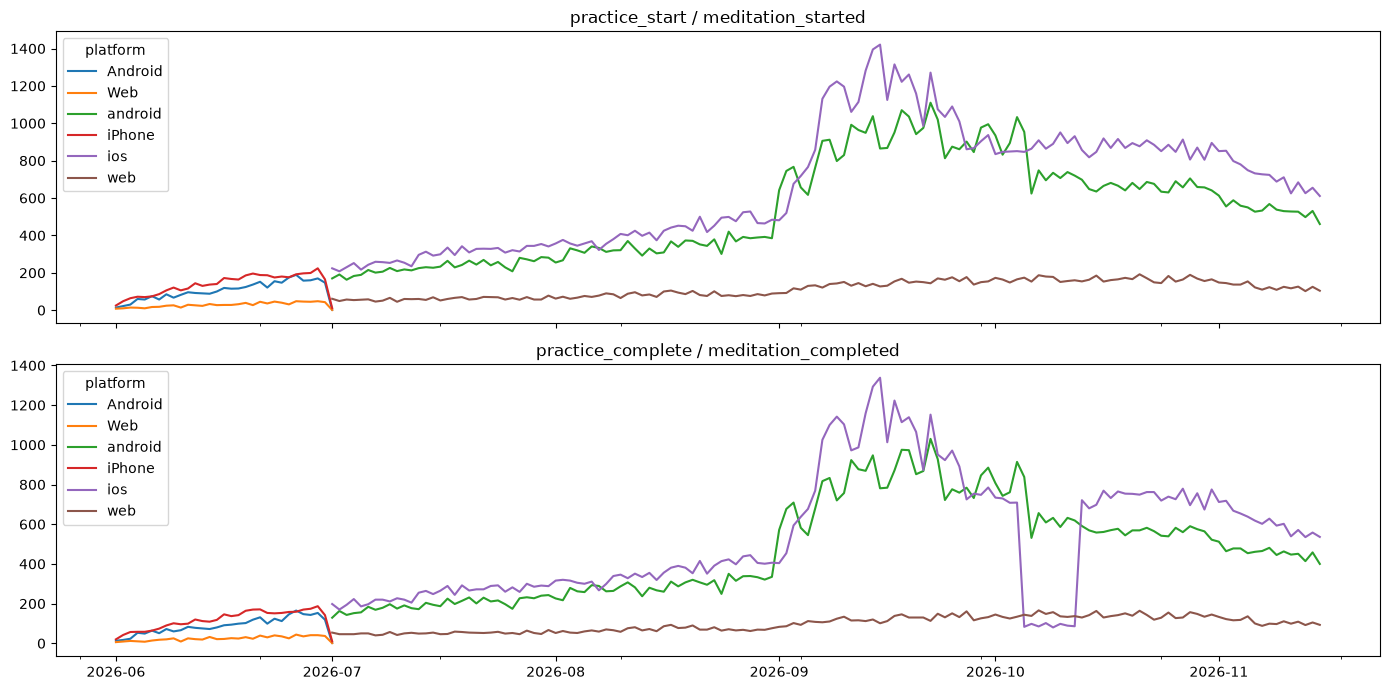

In [95]:
# Daily volume of key events by platform: look for drops, spikes, gaps
e = events.dropna(subset=["ts_parsed"])
e = e[(e.ts_parsed >= "2026-06-01") & (e.ts_parsed <= "2026-11-16")]
fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
for ax, names in zip(axes, [["practice_start", "meditation_started"], ["practice_complete", "meditation_completed"]]):
    sub = e[e.event_name.isin(names)]
    sub.groupby([sub.ts_parsed.dt.date, "platform"]).size().unstack().plot(ax=ax)
    ax.set_title(" / ".join(names)); ax.set_xlabel("")
plt.tight_layout(); plt.show()

In [96]:
# Orphans: events from users not in the users table
known = set(users.user_id)
orphan = events.user_id.notna() & ~events.user_id.isin(known)
print("orphan events:", orphan.sum())

orphan events: 0


In [99]:
ISSUES

[{'table': 'users',
  'column': 'user_id',
  'issue': "Legacy users duplicated by migration: copies labeled source_system='core'",
  'evidence': '15,146 rows vs 15,006 unique ids; 140 dupes, all L-prefixed ids signed up before 2026-07-01; copy has lowercase platform and signup_ts +1-90s',
  'severity': 'high',
  'proposed_fix': "Keep the legacy row, drop the 'core' copy"},
 {'table': 'users',
  'column': 'meditation_experience, primary_goal',
  'issue': 'Structurally missing: onboarding answers only exist if onboarding was completed',
  'evidence': '2,119 nulls in both columns, same users; matches users without an onboarding_complete event',
  'severity': 'medium',
  'proposed_fix': "Fill with 'not_answered' and add completed_onboarding flag; do not impute"},
 {'table': 'users',
  'column': 'age_band',
  'issue': 'Optional self-reported field, ~7% missing',
  'evidence': '1,052 nulls',
  'severity': 'low',
  'proposed_fix': "Use 'unknown' category; do not impute"},
 {'table': 'users/ev

---
## 3. `assessments`
❓ Do the `wave` labels match the README?
❓ Are all item values within the valid range? How often does the `99` code appear?
❓ Does any user have more than one submission for the same wave?
❓ Are there low-effort responses (very fast, or the same answer to every item)?
❓ **Psychometrics:** does every item correlate positively with the rest of its pillar once you apply the README's scoring rules? Try splitting the result by other columns.

In [100]:
profile(assess)

,column,n_null,pct_null,n_unique,examples
0,response_id,0,0.0,15574,"[r_000000, r_000001, r_000002, r_000003, r_000..."
1,user_id,0,0.0,11921,"[L106033, L107222, L110089, L114096, L102273]"
2,wave,0,0.0,4,"[intake, week4, baseline, week8]"
3,submitted_ts,0,0.0,15564,"[2026-06-01T06:47:00Z, 2026-06-01T06:54:01Z, 2..."
4,scoring_version,0,0.0,2,"[v1, v2]"
5,completion_seconds,0,0.0,566,"[16, 319, 290, 111, 256]"
6,q01,0,0.0,7,"[1, 3, 2, 4, 99]"
7,q02,0,0.0,8,"[1, 4, 2, 3, 5]"
8,q03,0,0.0,6,"[1, 3, 4, 2, 5]"
9,q04,0,0.0,7,"[1, 2, 5, 4, 3]"


In [101]:
print(pd.crosstab(assess.wave, assess.scoring_version), "\n")
items = [f"q{i:02d}" for i in range(1, 17)]
phq = [f"phq4_{i}" for i in range(1, 5)]
pd.concat({c: assess[c].value_counts() for c in items + phq}, axis=1).fillna(0).astype(int)

scoring_version    v1    v2
wave                       
baseline            0  9855
intake           1495     0
week4               4  2813
week8               0  1407 



,q01,q02,q03,q04,q05,q06,q07,q08,q09,q10,q11,q12,q13,q14,q15,q16,phq4_1,phq4_2,phq4_3,phq4_4
3,4892,4840,4886,4964,4968,4988,4894,4930,4883,4941,4911,4980,4888,4867,4805,4832,839,850,836,855
4,3803,3855,3780,3800,3789,3674,3792,3790,3761,3779,3766,3689,3790,3772,3856,3860,0,0,0,0
2,3319,3293,3325,3264,3252,3375,3352,3366,3341,3339,3341,3395,3355,3363,3356,3322,3485,3478,3491,3504
5,1926,1921,1956,1885,1878,1856,1897,1868,1893,1937,1909,1941,1859,1885,1832,1827,0,0,0,0
1,1413,1422,1410,1442,1438,1420,1366,1375,1464,1347,1418,1321,1448,1434,1454,1511,6091,6114,6052,6142
99,219,241,217,218,248,259,272,243,228,229,229,248,232,251,269,220,209,208,220,201
6,2,1,0,1,1,1,1,2,0,1,0,0,0,0,1,0,0,0,0,0
0,0,1,0,0,0,1,0,0,4,1,0,0,2,2,1,2,4950,4924,4975,4872


In [104]:
# print rows where any value is string '99'
assess[assess.isin(['99']).any(axis=1)]

,response_id,user_id,wave,submitted_ts,scoring_version,completion_seconds,q01,q02,q03,q04,q05,q06,q07,q08,q09,q10,q11,q12,q13,q14,q15,q16,phq4_1,phq4_2,phq4_3,phq4_4
5,r_000005,L102746,intake,2026-06-01T08:47:13Z,v1,188,3,2,3,3,4,99,3,1,5,5,5,3,4,4,3,2,3,1,1,1
7,r_000007,L111034,intake,2026-06-01T09:39:08Z,v1,367,3,4,3,1,5,3,5,1,3,3,2,3,3,3,3,4,2,1,2,99
8,r_000008,L114618,intake,2026-06-01T09:40:31Z,v1,130,3,2,2,4,3,3,2,4,99,4,4,1,2,4,3,2,0,0,0,0
11,r_000011,L112537,intake,2026-06-01T11:41:18Z,v1,142,2,2,1,4,3,99,3,4,2,4,3,5,2,2,2,2,3,3,1,2
16,r_000016,L103601,intake,2026-06-01T12:59:03Z,v1,527,99,5,5,3,4,4,4,2,5,5,4,2,5,5,5,1,2,1,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
15564,r_015564,u_d7064432c5,week8,2026-11-15T20:29:30Z,v2,134,5,5,4,5,5,3,4,4,2,2,99,3,3,4,4,2,3,2,3,2
15565,r_015565,u_9bdacdd859,week8,2026-11-15T20:51:21Z,v2,212,99,3,3,3,3,4,3,2,4,5,4,5,5,4,4,4,0,2,1,0
15567,r_015567,u_6d1c5c67cd,week4,2026-11-15T22:13:12Z,v2,151,5,5,4,5,5,3,99,5,5,4,5,4,5,5,5,5,0,1,0,0
15568,r_015568,u_29e5c04f65,week4,2026-11-15T22:40:29Z,v2,91,3,1,99,2,2,99,2,2,2,2,2,1,1,2,2,1,2,2,2,3


In [105]:
# print count of '99' columnwise
assess.isin(['99']).sum()

response_id             0
user_id                 0
wave                    0
submitted_ts            0
scoring_version         0
completion_seconds     56
q01                   219
q02                   241
q03                   217
q04                   218
q05                   248
q06                   259
q07                   272
q08                   243
q09                   228
q10                   229
q11                   229
q12                   248
q13                   232
q14                   251
q15                   269
q16                   220
phq4_1                209
phq4_2                208
phq4_3                220
phq4_4                201
dtype: int64

In [106]:
dup = assess.groupby(["user_id", "wave"]).size()
print(dup.value_counts())

1    14814
2      380
Name: count, dtype: int64


In [108]:
print(dup)

user_id       wave    
L100006       intake      1
L100016       intake      1
L100033       intake      1
              week4       1
L100034       intake      1
                         ..
u_fff5cdd3e9  week4       1
u_fff9dcac8b  baseline    1
u_fffc3a8cfe  baseline    1
              week4       1
              week8       1
Length: 15194, dtype: int64


In [107]:
A = assess.copy()
A[items + phq] = A[items + phq].astype(int).replace(99, np.nan)
A["completion_seconds"] = A.completion_seconds.astype(int)
A["item_sd"] = A[items].std(axis=1)
print(A.completion_seconds.describe(percentiles=[.01, .05, .5, .95]))
print("zero-variance (straight-line) responses:", (A.item_sd == 0).sum())

count    15574.000000
mean       199.334403
std         90.234421
min         12.000000
1%          21.000000
5%          84.000000
50%        186.000000
95%        363.350000
max        828.000000
Name: completion_seconds, dtype: float64
zero-variance (straight-line) responses: 457


In [109]:
# Item-rest correlation, scored per the README (reverse q04, q08, q12, q16)
def item_rest(df):
    X = df[items].where((df[items] >= 1) & (df[items] <= 5))
    for q in ["q04", "q08", "q12", "q16"]:
        X[q] = 6 - X[q]
    out = {}
    for p, block in enumerate([items[i:i+4] for i in range(0, 16, 4)]):
        for q in block:
            rest = X[[b for b in block if b != q]].mean(axis=1)
            out[q] = X[q].corr(rest)
    return pd.Series(out).round(2)

item_rest(A).to_frame("all_rows")
# ❓ Now try: item_rest on subsets of A (e.g., by a version or system column). Anything change?

,all_rows
q01,0.45
q02,0.44
q03,0.44
q04,-0.57
q05,0.43
q06,0.43
q07,0.44
q08,-0.56
q09,0.45
q10,0.45


---
## 4. `experiment_assignments`
❓ Is each user assigned exactly once? Is anyone in **both** variants?
❓ Is the split really 50/50? Run a **Sample Ratio Mismatch (SRM)** test.
❓ If there's a mismatch, where does it come from? Think about how to get every user who *should* have been assigned, using the eligibility rule in the README.

In [111]:
assign.head()

,assignment_id,user_id,experiment_id,variant,assigned_ts
0,a_00000,u_708547951d,onb_personal_plan_v1,control,2026-09-01T06:03:41Z
1,a_00001,u_a1b83728d2,onb_personal_plan_v1,control,2026-09-01T06:06:53Z
2,a_00002,u_b28a256e9a,onb_personal_plan_v1,treatment,2026-09-01T06:14:14Z
3,a_00003,u_a4ff7a2e01,onb_personal_plan_v1,treatment,2026-09-01T06:14:27Z
4,a_00004,u_9a7d9f979e,onb_personal_plan_v1,treatment,2026-09-01T06:14:38Z


In [110]:
print("rows:", len(assign), "| unique users:", assign.user_id.nunique())
print("exact duplicate rows:", assign.duplicated(subset=["user_id", "variant", "assigned_ts"]).sum())
nvar = assign.groupby("user_id").variant.nunique()
print("users in both variants:", (nvar > 1).sum())

rows: 4306 | unique users: 4227
exact duplicate rows: 51
users in both variants: 28


In [112]:
# SRM check on first assignment per user
first = assign.sort_values("assigned_ts").drop_duplicates("user_id")
counts = first.variant.value_counts()
chi = stats.chisquare(counts.values)
print(counts.to_string()); print(f"SRM chi-square p = {chi.pvalue:.2e}")

variant
control      2241
treatment    1986
SRM chi-square p = 8.78e-05


In [113]:
# Coverage: eligible users (per README rule) vs logged assignments
u = users.drop_duplicates("user_id").copy()
u["signup"] = pd.to_datetime(u.signup_ts, utc=True)
eligible = u[(u.signup >= "2026-09-01") & (u.signup < "2026-10-01") & u.platform.str.lower().isin(["ios", "android"])]
eligible = eligible.assign(assigned=eligible.user_id.isin(set(assign.user_id)))
print("eligible:", len(eligible), "| assigned:", eligible.assigned.sum())
eligible.groupby(["platform", "signup_app_version"]).assigned.agg(["size", "mean"]).round(3)

eligible: 4422 | assigned: 4227


size   mean
platform signup_app_version             
android  4.9.0                 42  1.000
         5.0.0                511  0.994
         5.1.0                857  0.779
         5.1.1                544  1.000
ios      4.9.0                 70  1.000
         5.0.0                703  0.996
         5.1.0               1695  1.000

In [115]:
qa_ids = set(users.loc[users.acquisition_channel == "unknown", "user_id"])

In [116]:
missing = eligible[~eligible.assigned & ~eligible.user_id.isin(qa_ids)]
print(len(missing)); print(missing.groupby(["platform", "signup_app_version"]).size())

ev = events[events.user_id.isin(missing.user_id)]
print(ev.event_name.value_counts())
print(ev[ev.event_name == "onboarding_start"].properties.value_counts())
print(ev.groupby("user_id").size().describe())

189
platform  signup_app_version
android   5.1.0                 189
dtype: int64
event_name
app_open            232
app_install         197
onboarding_start    197
Name: count, dtype: int64
properties
{"flow": "personal_plan"}    197
Name: count, dtype: int64
count    189.000000
mean       3.312169
std        0.497772
min        3.000000
25%        3.000000
50%        3.000000
75%        4.000000
max        5.000000
dtype: float64


---
## 5. `content` & `marketing_spend`
❓ Does every `content_id` that appears in events exist in the catalog?
❓ How do the platform-reported installs compare with the signups in `users`?

In [117]:
content.head()

,content_id,content_type,pillar,duration_min,release_date
0,c_001,lesson,purpose,3,2025-04-16
1,c_002,seated_meditation,awareness,15,2024-05-15
2,c_003,lesson,awareness,7,2025-01-03
3,c_004,active_meditation,connection,15,2026-03-14
4,c_005,seated_meditation,connection,5,2026-01-17


In [118]:
print(profile(content))
ids_in_events = set(events.properties.map(lambda p: json.loads(p).get("content_id") or json.loads(p).get("contentId")).dropna())
print("content ids in events not in catalog:", len(ids_in_events - set(content.content_id)))

         column  n_null  pct_null  n_unique                                           examples
0    content_id       0       0.0       120                [c_001, c_002, c_003, c_004, c_005]
1  content_type       0       0.0         3     [lesson, seated_meditation, active_meditation]
2        pillar       0       0.0         4          [purpose, awareness, connection, insight]
3  duration_min       0       0.0         7                                  [3, 15, 7, 5, 20]
4  release_date       0       0.0       114  [2025-04-16, 2024-05-15, 2025-01-03, 2026-03-1...
content ids in events not in catalog: 0


In [119]:
m = mkt.astype({"spend_usd": float, "attributed_installs": int})
paid = u[u.acquisition_channel.isin(["paid_social", "app_store_search"])]
first_party = paid.groupby("acquisition_channel").size()
summary = m.groupby("channel")[["spend_usd", "attributed_installs"]].sum().join(first_party.rename("signups_in_users"))
summary["cac_platform"] = summary.spend_usd / summary.attributed_installs
summary["cac_first_party"] = summary.spend_usd / summary.signups_in_users
summary.round(2)

,spend_usd,attributed_installs,signups_in_users,cac_platform,cac_first_party
channel,,,,,
app_store_search,29079.99,3020,2664,9.63,10.92
paid_social,54608.01,4199,3655,13.01,14.94


In [120]:
# print content_id from events df which has dictionary items of contentId in properties column
import ast
content_ids = events[events.properties.str.contains("contentId", na=False)].properties.apply(lambda x: ast.literal_eval(x).get("contentId"))
print(content_ids)
print(content_ids.value_counts())

130630    c_026
130638    c_021
130645    c_021
130657    c_026
130658    c_026
          ...  
603897    c_079
603898    c_062
603902    c_033
603903    c_083
603904    c_037
Name: properties, Length: 271219, dtype: object
properties
c_012    2835
c_091    2732
c_058    2722
c_113    2683
c_073    2678
         ... 
c_069    1970
c_103    1954
c_116    1953
c_059    1945
c_007    1886
Name: count, Length: 120, dtype: int64


---
## 6. Wrap-up: save the issue log
Export the issue log. Every finding above should have a matching `log_issue(...)` entry.

In [ ]:
# ===== Step 1: Final data-quality issue log =====
# Paste into the last section of 01_data_profiling.ipynb (replaces ISSUES) and run.

ISSUES = [
    # ---------------- users ----------------
    dict(id=1, table="users", column="user_id",
         issue="Legacy users duplicated by the July migration; copies labeled source_system='core'",
         evidence="15,146 rows vs 15,006 unique ids; 140 dupes, all L-prefixed ids that signed up before 2026-07-01; "
                  "the copy has a lowercase platform and signup_ts +1-90s",
         severity="high",
         proposed_fix="Keep the legacy row, drop the 'core' copy"),
    dict(id=2, table="users", column="platform",
         issue="Inconsistent platform labels across systems",
         evidence="Legacy labels iPhone/Android/Web (948/752/229) alongside ios/android/web",
         severity="medium",
         proposed_fix="Map to lowercase ios/android/web"),
    dict(id=3, table="users", column="meditation_experience, primary_goal",
         issue="Structurally missing: onboarding answers exist only if onboarding was completed",
         evidence="2,119 nulls in both columns for the same users; they have no onboarding_complete event",
         severity="medium",
         proposed_fix="Fill with 'not_answered' and add a completed_onboarding flag; do not impute"),
    dict(id=4, table="users", column="age_band",
         issue="Optional self-reported field, partially missing",
         evidence="1,052 nulls (~7%)",
         severity="low",
         proposed_fix="Use an 'unknown' category; do not impute"),
    dict(id=5, table="users/events", column="user_id",
         issue="6 internal/test accounts mixed in with real users",
         evidence="acquisition_channel='unknown' (not a documented channel); no install/onboarding events; no profile; "
                  "80-300 practices/day at ~5s each; max 605 events/day vs p99.9 = 14 for real users; "
                  "39,462 events = 15.7% of all practice_complete events; cause of the late-August spike",
         severity="high",
         proposed_fix="Exclude from all tables; keep an is_internal flag for traceability"),

    # ---------------- events ----------------
    dict(id=6, table="events", column="event_ts",
         issue="Two timestamp formats; legacy events stored as naive LOCAL time with no timezone",
         evidence="31,891 events in 'YYYY-MM-DD HH:MM:SS' format, all with legacy platform labels and before 2026-07-01; "
                  "all others are ISO-8601 UTC with ms + 'Z'",
         severity="high",
         proposed_fix="Localize naive timestamps with users.timezone, convert to UTC, then unify"),
    dict(id=7, table="events", column="event_name, properties",
         issue="Schema drift between tracking plan v1 and v2 (event names, property keys, units)",
         evidence="v1 (app 4.x): meditation_started/meditation_completed with content_id/duration_sec; "
                  "v2 (app 5.x): practice_start/practice_complete with contentId/durationMs; "
                  "median duration 602 (v1) vs 556,000 (v2) = seconds vs milliseconds; "
                  "~36k v1 completes would be lost by filtering on 'practice_complete'",
         severity="high",
         proposed_fix="Map v1 names to v2; parse JSON into content_id and duration_sec columns; convert ms to s"),
    dict(id=8, table="events", column="all",
         issue="Duplicate events from client retries (a new event_id on every resend)",
         evidence="163 exact + 10,691 near-dupes (same user/event/session/properties within 3s); ~71% on Android",
         severity="high",
         proposed_fix="Keep the first of any identical events within 3s"),
    dict(id=9, table="events", column="platform",
         issue="Inconsistent platform labels (same as users)",
         evidence="iPhone/Android/Web on legacy events",
         severity="low",
         proposed_fix="Map to ios/android/web"),
    dict(id=10, table="events", column="user_id",
         issue="Events with no user_id (pre-login)",
         evidence="664 events, all app_open",
         severity="low",
         proposed_fix="Exclude from user-level analysis"),
    dict(id=11, table="events", column="event_ts",
         issue="Device clock skew: impossible dates",
         evidence="938 events dated 2001 and 940 dated 2027 (~0.3%); valid window is 2026-06-01 to 2026-11-15",
         severity="medium",
         proposed_fix="Drop events outside [signup_ts, data cutoff]"),
    dict(id=12, table="events", column="event_name",
         issue="Tracking gap: iOS app 5.2.0 did not send practice_complete from Oct 5-12 (not a real engagement drop)",
         evidence="iOS practice_start steady (~850-950/day) but practice_complete fell from ~730/day to ~90/day; "
                  "complete/start ratio 0.84 -> 0.10; in that window 5.2.0 logged 6,254 starts and 0 completes, "
                  "while 5.1.0 logged normally",
         severity="high",
         proposed_fix="Flag the window; for practice-day features use practice_start as the activity signal on affected "
                      "iOS days (or exclude the window); never report the dip as an engagement trend"),

    # ---------------- assessments ----------------
    dict(id=13, table="assessments", column="wave",
         issue="Legacy wave label 'intake' means 'baseline'",
         evidence="1,495 'intake' rows, all scoring_version v1 (June signups)",
         severity="medium",
         proposed_fix="Map 'intake' -> 'baseline'"),
    dict(id=14, table="assessments", column="q01-q16",
         issue="Invalid item values: 99 = skipped, plus out-of-range 0/6",
         evidence="3,823 cells = 99 (~1.5%); 25 cells = 0 or 6, all in v1",
         severity="medium",
         proposed_fix="Set to missing; score a pillar only if at least 3 of its 4 items are present"),
    dict(id=15, table="assessments", column="user_id, wave",
         issue="Duplicate submissions for the same user and wave (resubmissions)",
         evidence="380 user-waves with 2 submissions, 1-29 min apart (median 15) and a couple of items changed",
         severity="medium",
         proposed_fix="Keep the latest submission"),
    dict(id=16, table="assessments", column="q01-q16, completion_seconds",
         issue="Low-effort responses (straight-lining and speeding)",
         evidence="457 identical answers on all 16 items; 468 completed in under 40s; 453 are both "
                  "(p1 = 21s vs p50 = 186s)",
         severity="medium",
         proposed_fix="Flag responses that are both zero-variance and under 40s; exclude from outcome analysis, "
                      "and run a sensitivity check with them included"),
    dict(id=17, table="assessments", column="q04, q08, q12, q16",
         issue="Undocumented scoring change: v2 stores reverse-worded items already reversed, "
               "so the documented rule (6 - x) double-reverses them",
         evidence="Item-rest correlation of reverse items after applying the documented rule: about -0.57 overall; "
                  "positive in v1, negative in v2; v2 = ~90% of submissions",
         severity="high",
         proposed_fix="Apply 6 - x to reverse items for v1 only; confirm with item-rest correlations and "
                      "Cronbach's alpha by version; flag to the measurement-spec owner"),

    # ---------------- experiment_assignments ----------------
    dict(id=18, table="experiment_assignments", column="all",
         issue="Exact duplicate assignment rows",
         evidence="51 rows",
         severity="low",
         proposed_fix="Drop exact duplicates"),
    dict(id=19, table="experiment_assignments", column="variant",
         issue="Users assigned to both variants",
         evidence="28 users with a second, opposite assignment days later (likely reinstall)",
         severity="medium",
         proposed_fix="Keep each user's first assignment (intention-to-treat)"),
    dict(id=20, table="experiment_assignments", column="variant",
         issue="Sample Ratio Mismatch: treatment users on Android 5.1.0 never got an assignment logged",
         evidence="Logged 2,241 control vs 1,986 treatment (chi-square p ~ 9e-5); 195 eligible users unassigned "
                  "= 6 test accounts + 189 real users, ALL on Android 5.1.0; all 189 have onboarding_start "
                  "flow='personal_plan' (= treatment) and a median of 3 events total (abandoned during the new onboarding); "
                  "with the arm rebuilt from the onboarding flow the split is 2,241 vs 2,175 (p ~ 0.32, balanced)",
         severity="high",
         proposed_fix="Rebuild assignment for all eligible users from onboarding_start.flow; analyze as "
                      "intention-to-treat including the 189; report Android 5.1.0 separately; flag the build to Engineering"),

    # ---------------- content & marketing ----------------
    dict(id=21, table="content", column="all",
         issue="PASS: no issues found",
         evidence="120 unique content_ids; every content_id in events exists in the catalog",
         severity="none",
         proposed_fix="None"),
    dict(id=22, table="marketing_spend", column="attributed_installs",
         issue="Ad platforms over-attribute installs compared with first-party signups",
         evidence="app_store_search: 3,020 attributed vs 2,664 signups (+13%); "
                  "paid_social: 4,199 vs 3,655 (+15%)",
         severity="medium",
         proposed_fix="Report CAC on first-party signups (ASA ~$10.92, paid social ~$14.94); "
                      "treat platform numbers as an upper bound"),
]

log = pd.DataFrame(ISSUES)
log.to_csv(REPORTS / "data_quality_log.csv", index=False)
print(log.severity.value_counts())
log[["id", "table", "issue", "severity"]]

---
## Summary of findings
_Summarize the main issues here, ranked by severity, and say which analyses each one affects._